# Legitimate Academic Announcements vs. Spam: TF-IDF vs. Sentence Embeddings
**NLP Course Project - Option 1 (Spam Detection), Ling-Spam dataset**

**Runtime:** Google Colab (also runs on local Jupyter). Run all cells in order from a fresh session.

**Experimental question:** Which method more reliably distinguishes legitimate academic announcements containing promotional vocabulary from genuine spam: TF-IDF + logistic regression, or pretrained sentence embeddings (all-MiniLM-L6-v2) + logistic regression?

| Section | Owner |
|---|---|
| Setup, Data, Method 1 (TF-IDF) | Abrar |
| Method 2 (sentence embeddings), Try it for Method 2, reproducibility check | Jana |
| Results (challenge subset, metrics, false-positive analysis, error analysis) | Zahra |


## 1. Setup

In [1]:
import sys, os, subprocess, random
import numpy as np

# --- Colab: install pinned versions and fetch the project files ---------------
# Versions below are the ones this project was developed and tested with.
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                    "scikit-learn==1.9.1", "pandas==3.0.5", "numpy==2.5.3",
                    "scipy==1.18.1", "joblib==1.6.0"], check=True)
    # TODO (Abrar): replace with the real GitHub repo URL before submitting
    REPO_URL = "https://github.com/AbrarAlmutawa/Distinguishing-Legitimate-Announcements-from-Spam-TF-IDF-vs.-Sentence-Embeddings.git"
    REPO_DIR = REPO_URL.rstrip("/").split("/")[-1].removesuffix(".git")
    if not os.path.exists("data_utils.py"):
        if not os.path.exists(REPO_DIR):
            subprocess.run(["git", "clone", REPO_URL], check=True)
        os.chdir(REPO_DIR)   # all later paths are relative to the repo root

# --- Reproducibility -----------------------------------------------------------
SEED = 42
random.seed(SEED); np.random.seed(SEED)

import sklearn, pandas as pd, scipy, joblib
print("python", sys.version.split()[0], "| sklearn", sklearn.__version__,
      "| pandas", pd.__version__, "| numpy", np.__version__)
print("working directory:", os.getcwd())
assert os.path.exists("data/messages.csv"), "data/messages.csv not found - run from the repo root"

python 3.13.18 | sklearn 1.9.1 | pandas 3.0.5 | numpy 2.4.6
working directory: /content/Distinguishing-Legitimate-Announcements-from-Spam-TF-IDF-vs.-Sentence-Embeddings


## 2. Data
**Source:** Ling-Spam corpus, Kaggle version (`messages.csv`). Columns: `subject`, `message`, `label` (0 = legitimate, 1 = spam).

Steps (feedback points 4 and 5):
1. Verify the format: separate `subject` and `message` fields exist, so the model input is `subject + " " + message`.
2. Normalise (lowercase, collapse whitespace) and remove exact duplicates.
3. Group near-duplicates (TF-IDF cosine similarity > 0.9) with connected components.
4. Stratified 70/15/15 split in which every near-duplicate group stays inside one partition.
5. Programmatically verify that no group or text crosses partitions.

In [22]:
import json
import data_utils as du

raw = du.load_raw("data/messages.csv")
print("columns:", list(raw.columns[:3]), "| rows:", len(raw))
print("class counts (0 = legitimate, 1 = spam):", raw["label"].value_counts().to_dict())
print("messages with an empty subject:", int((raw["subject"].str.strip() == "").sum()))
raw[["subject", "message", "label"]].head(3)

columns: ['subject', 'message', 'label'] | rows: 2893
class counts (0 = legitimate, 1 = spam): {0: 2412, 1: 481}
messages with an empty subject: 62


,subject,message,label
0,job posting - apple-iss research center,content - length : 3386 apple-iss research cen...,0
1,,"lang classification grimes , joseph e . and ba...",0
2,query : letter frequencies for text identifica...,i am posting this inquiry for sergei atamas ( ...,0


In [ ]:
clean, exact_info = du.drop_exact_duplicates(raw)
print(exact_info)

clean["group"], near_info = du.near_duplicate_groups(clean, threshold=0.9)
print(near_info)

clean["split"] = du.grouped_stratified_split(clean)
train, dev, test = (clean[clean["split"] == s].reset_index(drop=True) for s in ("train", "dev", "test"))
du.check_no_leakage(train, dev, test)
print("leakage check passed: no group or normalised text shared across partitions")
pd.DataFrame(du.summarise_splits(train, dev, test)).T

{'exact_duplicates_removed': 17, 'removed_spam': 13, 'removed_legit': 4, 'exact_duplicate_texts_with_conflicting_labels': 0}
{'near_dup_threshold': 0.9, 'near_dup_groups_with_2plus_messages': 141, 'messages_in_near_dup_groups': 319, 'largest_group_size': 5}
leakage check passed: no group or normalised text shared across partitions


,n,spam,legit,spam_share
train,2014.0,326.0,1688.0,0.1619
dev,430.0,70.0,360.0,0.1628
test,432.0,72.0,360.0,0.1667


In [ ]:
# Save the partitions (the committed copies in data/ are identical because everything is seeded)
cols = ["subject", "message", "text", "label", "group"]
for name, part in (("train", train), ("dev", dev), ("test", test)):
    part[cols].to_csv(f"data/{name}.csv", index=False)

## 3. Method 1 - TF-IDF + Logistic Regression (traditional)
TF-IDF turns each message into a weighted bag of words; logistic regression classifies it. Both come from scikit-learn (no pretrained weights).

Only the **training** set is used to fit and only the **development** set to choose settings: n-gram range, `min_df`, `C` and the decision threshold. The test set is not loaded in this section.

In [ ]:
import baseline_tfidf as m1

tfidf_model, tfidf_cfg, grid = m1.run(save=True, verbose=False)
print("top of the dev grid (24 combinations tried):")
display(grid.head(8))
print("selected settings:", {k: tfidf_cfg[k] for k in ("ngram_range", "min_df", "C", "threshold")})
print(f"DEV macro F1 {tfidf_cfg['dev_macro_f1']} | DEV accuracy {tfidf_cfg['dev_accuracy']} | "
      f"DEV false positives {tfidf_cfg['dev_false_positives']} | DEV false negatives {tfidf_cfg['dev_false_negatives']}")

top of the dev grid (24 combinations tried):


,ngram_range,min_df,C,dev_macro_f1,dev_accuracy
2,"(1, 1)",1,10.0,0.995709,0.997674
3,"(1, 1)",1,100.0,0.995709,0.997674
7,"(1, 1)",2,100.0,0.995709,0.997674
11,"(1, 1)",3,100.0,0.995709,0.997674
6,"(1, 1)",2,10.0,0.991369,0.995349
10,"(1, 1)",3,10.0,0.991369,0.995349
5,"(1, 1)",2,1.0,0.986976,0.993023
9,"(1, 1)",3,1.0,0.986976,0.993023


selected settings: {'ngram_range': [1, 1], 'min_df': 1, 'C': 10.0, 'threshold': 0.5}
DEV macro F1 0.9957 | DEV accuracy 0.9977 | DEV false positives 0 | DEV false negatives 1


Saved to `models/tfidf_lr.joblib` (pipeline) and `models/tfidf_lr_config.json` (settings and threshold) so the **Try it** section can load the model without retraining.

## 4. Method 2 - Sentence embeddings + Logistic Regression (pretrained)
**Owner: Jana.** Code: `embed_sbert.py`.

1. **Encoder (pretrained, frozen):** `sentence-transformers/all-MiniLM-L6-v2` (Reimers and Gurevych, 2019) maps each message (`subject + " " + message`, same input as Method 1) to a 384-dimensional, L2-normalised sentence embedding. We do not fine-tune it; the weights are downloaded from Hugging Face on first use.
2. **Classifier:** logistic regression (scikit-learn) with balanced class weights, trained on the **training** embeddings only.
3. **Tuning on dev only:** `C` from {0.01, 0.1, 1, 10, 100} is picked by dev macro F1, then the decision threshold is picked on dev with the same rule as Method 1 (ties go to the higher threshold, which means fewer false positives).
4. **Saved for reuse:** `models/sbert_lr.joblib` (classifier) and `models/sbert_lr_config.json` (settings, threshold, encoder revision). Embeddings are cached in `data/emb_cache/`.

The test set is not loaded in this section.

**Limitation:** the encoder reads at most 256 word-piece tokens, so a long email is represented by its subject and the start of its body.


In [ ]:
# Colab: install the Method 2 packages (pinned; same versions as requirements.txt)
if IN_COLAB:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                    "sentence-transformers==6.3.0", "transformers==5.24.1"], check=True)

import torch, sentence_transformers, transformers
torch.manual_seed(SEED)
print("sentence-transformers", sentence_transformers.__version__, "| transformers", transformers.__version__,
      "| torch", torch.__version__, "| device:", "cuda" if torch.cuda.is_available() else "cpu")

import embed_sbert as m2

sbert_model, sbert_cfg, sbert_grid = m2.run(save=True, verbose=False)
print(f"dev grid ({sbert_cfg['grid_combinations_tried']} values of C tried):")
display(sbert_grid)
print("selected settings:", {k: sbert_cfg[k] for k in ("C", "threshold")},
      "| encoder revision:", sbert_cfg["encoder_revision"])
print(f"DEV macro F1 {sbert_cfg['dev_macro_f1']} | DEV accuracy {sbert_cfg['dev_accuracy']} | "
      f"DEV false positives {sbert_cfg['dev_false_positives']} | DEV false negatives {sbert_cfg['dev_false_negatives']}")


sentence-transformers 6.3.0 | transformers 5.24.1 | torch 2.14.1+cu130 | device: cuda


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

... (9 outputs left out)

Batches:   0%|          | 0/7 [00:00<?, ?it/s]

dev grid (5 values of C tried):


,C,dev_macro_f1,dev_accuracy
3,10.00,0.987128,0.993023
4,100.00,0.987128,0.993023
2,1.00,0.983130,0.990698
0,0.01,0.975250,0.986047
1,0.10,0.975250,0.986047


selected settings: {'C': 10.0, 'threshold': 0.45} | encoder revision: None
DEV macro F1 0.9873 | DEV accuracy 0.993 | DEV false positives 2 | DEV false negatives 1


## 5. Results
**Owner: Zahra.** Run the test set **once**, after both models are final.
- Accuracy, macro F1 and confusion matrices on the identical test set.
- Challenge subset: legitimate test messages passing the keyword filter, then verified by hand as academic announcements. Document the rules and the count, and fix the subset before looking at predictions.
- Number of false positives and False Positive Rate (FPR) on the subset, for both models.
- Error analysis (3+ wrong predictions, or all of them plus difficult correct cases) and limitations (small subset, so FPR is noisy).

In [2]:
import pandas as pd
import re


test = pd.read_csv("data/test.csv")

legit = test[test["label"] == 0].copy()
pattern = (
    r"\b(?:free|register(?:ed|ing)?|registration|"
    r"deadlines?|opportunit(?:y|ies)|"
    r"calls?\s+for\s+(?:papers|abstracts|proposals|participation))\b"
)


candidates = legit[
    legit["text"].str.contains(pattern, case=False, regex=True, na=False)
].copy()

print("Total test emails:", len(test))
print("Legitimate test emails:", len(legit))
print("Keyword-matched candidates:", len(candidates))

display(candidates[["subject", "label"]].head(10))

Total test emails: 432
Legitimate test emails: 360
Keyword-matched candidates: 145


,subject,label
0,call for abstracts : optimality in syntactic t...,0
8,ceth summer seminar on electronic texts in the...,0
23,6 . 136 language and species,0
26,"re : 6 . 1101 , qs : literary texts on cd , j ...",0
30,tilburg conference on ot,0
32,re : 6 . 108 sum : words that are their own op...,0
33,m . a . in scandinavian linguistics,0
34,fifth international conference on chinese ling...,0
35,call for papers,0
44,sentence processing conference - schedule,0


In [3]:
pd.set_option("display.max_rows", None)
pd.set_option("display.max_colwidth", None)

display(candidates[["subject"]])

,subject
0,call for abstracts : optimality in syntactic theory
8,ceth summer seminar on electronic texts in the humanities
23,6 . 136 language and species
26,"re : 6 . 1101 , qs : literary texts on cd , j . roscoe , maya / mayan lg"
30,tilburg conference on ot
32,re : 6 . 108 sum : words that are their own opposites ( part 2 )
33,m . a . in scandinavian linguistics
34,fifth international conference on chinese linguistics
35,call for papers
44,sentence processing conference - schedule


Challenge Subset — Selection Criteria
The challenge subset was constructed from the legitimate emails in the held-out test set using a two-stage selection process:
1. Keyword-based filtering using promotional vocabulary and expressions.
2. Content-based verification to identify genuine academic announcements, including conferences, workshops, seminars, calls for papers, academic programs, and academic job opportunities.
General discussions, replies, commercial advertisements, non-academic recruitment announcements, and incidental uses of promotional keywords were excluded. Subset selection was conducted independently of

In [5]:

excluded_indices = [
    23, 26, 32, 80, 81, 95, 133,
    172, 216, 224, 245, 336, 339,
    347, 356, 402, 410, 416, 418
]

challenge_subset = candidates[
    ~candidates.index.isin(excluded_indices)
].copy()

assert (challenge_subset["label"] == 0).all()

print("Keyword-matched candidates:", len(candidates))
print("Excluded emails:", len(candidates) - len(challenge_subset))
print("Proposed challenge subset:", len(challenge_subset))

Keyword-matched candidates: 145
Excluded emails: 19
Proposed challenge subset: 126


In [8]:

challenge_subset.index.name = "test_index"

challenge_subset.to_csv(
    "data/challenge_subset.csv",
    index=True
)

# Validate the final subset
assert challenge_subset.index.is_unique
assert (challenge_subset["label"] == 0).all()
assert len(challenge_subset) == 126

print("Challenge subset successfully saved.")
print("Final subset size:", len(challenge_subset))
print("Selection completed before model predictions.")

Challenge subset successfully saved.
Final subset size: 126
Selection completed before model predictions.


In [9]:
!pip install -q sentence-transformers==6.3.0 transformers==5.24.1

In [10]:
import json
import joblib
import numpy as np
import embed_sbert as m2

# Load Method 1
tfidf_model = joblib.load("models/tfidf_lr.joblib")

with open("models/tfidf_lr_config.json") as f:
    tfidf_cfg = json.load(f)

# Load Method 2
sbert_model, sbert_cfg = m2.load_saved()

print("Method 1 loaded successfully.")
print("Method 1 threshold:", tfidf_cfg["threshold"])

print("Method 2 loaded successfully.")
print("Method 2 threshold:", sbert_cfg["threshold"])

Method 1 loaded successfully.
Method 1 threshold: 0.5
Method 2 loaded successfully.
Method 2 threshold: 0.45


In [11]:

y_true = test["label"].to_numpy()

tfidf_probs = tfidf_model.predict_proba(test["text"])[:, 1]

tfidf_preds = (
    tfidf_probs >= tfidf_cfg["threshold"]
).astype(int)

sbert_probs = m2.predict_proba_texts(
    test["text"], sbert_model, sbert_cfg
)

sbert_preds = (
    sbert_probs >= sbert_cfg["threshold"]
).astype(int)


results = test[["subject", "message", "label"]].copy()

results["tfidf_probability"] = tfidf_probs
results["tfidf_prediction"] = tfidf_preds

results["sbert_probability"] = sbert_probs
results["sbert_prediction"] = sbert_preds

results.index.name = "test_index"
results.to_csv("data/test_predictions.csv", index=True)

print("Final test predictions completed.")
print("Method 1 predictions:", len(tfidf_preds))
print("Method 2 predictions:", len(sbert_preds))

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 90.9MB            

... (4 outputs left out)

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Final test predictions completed.
Method 1 predictions: 432
Method 2 predictions: 432


**Accuracy and Macro F1**

In [12]:
from sklearn.metrics import accuracy_score, f1_score

overall_results = pd.DataFrame({
    "Model": ["TF-IDF + LR", "MiniLM + LR"],
    "Accuracy": [
        accuracy_score(y_true, tfidf_preds),
        accuracy_score(y_true, sbert_preds)
    ],
    "Macro F1": [
        f1_score(y_true, tfidf_preds, average="macro"),
        f1_score(y_true, sbert_preds, average="macro")
    ]
})

display(overall_results.round(4))

,Model,Accuracy,Macro F1
0,TF-IDF + LR,0.9977,0.9958
1,MiniLM + LR,0.9977,0.9959


**Confusion Matrices**

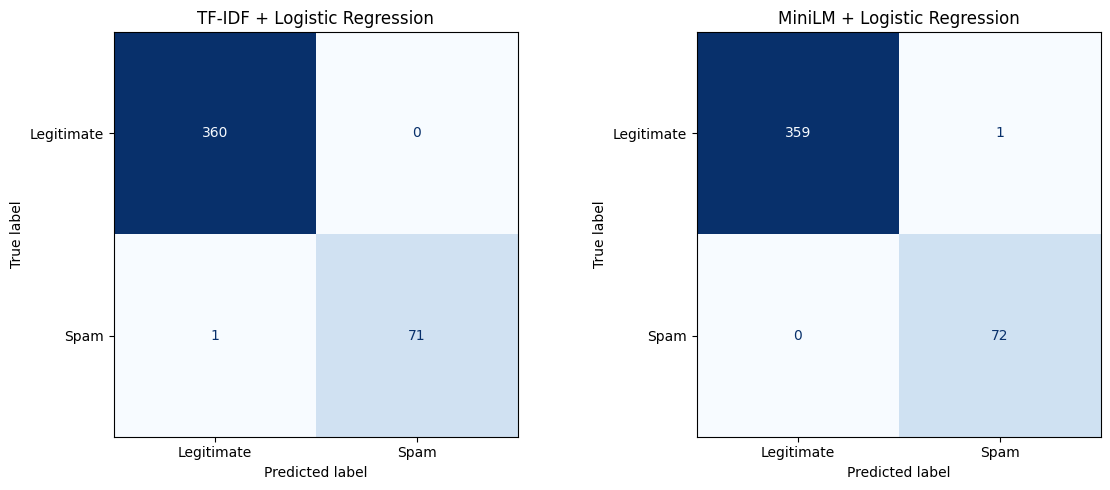

In [13]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

models = [
    ("TF-IDF + Logistic Regression", tfidf_preds),
    ("MiniLM + Logistic Regression", sbert_preds)
]

for ax, (name, preds) in zip(axes, models):
    cm = confusion_matrix(y_true, preds, labels=[0, 1])

    ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["Legitimate", "Spam"]
    ).plot(ax=ax, cmap="Blues", colorbar=False)

    ax.set_title(name)

plt.tight_layout()
plt.savefig("overall_confusion_matrices.png", dpi=300,
            bbox_inches="tight")
plt.show()

In [14]:

challenge_results = results.loc[challenge_subset.index].copy()

assert len(challenge_results) == 126
assert (challenge_results["label"] == 0).all()

n = len(challenge_results)


tfidf_fp = int((challenge_results["tfidf_prediction"] == 1).sum())
sbert_fp = int((challenge_results["sbert_prediction"] == 1).sum())


challenge_metrics = pd.DataFrame({
    "Model": ["TF-IDF + LR", "MiniLM + LR"],
    "Subset Size": [n, n],
    "True Negatives": [n - tfidf_fp, n - sbert_fp],
    "False Positives": [tfidf_fp, sbert_fp],
    "FPR (%)": [
        (tfidf_fp / n) * 100,
        (sbert_fp / n) * 100
    ]
})

display(challenge_metrics.round(4))

,Model,Subset Size,True Negatives,False Positives,FPR (%)
0,TF-IDF + LR,126,126,0,0.0
1,MiniLM + LR,126,126,0,0.0


In [15]:

errors = results[
    (results["tfidf_prediction"] != results["label"]) |
    (results["sbert_prediction"] != results["label"])
].copy()

errors["in_challenge_subset"] = errors.index.isin(
    challenge_subset.index
)

display(errors[[
    "subject",
    "label",
    "tfidf_prediction",
    "tfidf_probability",
    "sbert_prediction",
    "sbert_probability",
    "in_challenge_subset"
]].round(4))

print("Total unique misclassified emails:", len(errors))

,subject,label,tfidf_prediction,tfidf_probability,sbert_prediction,sbert_probability,in_challenge_subset
test_index,,,,,,,
26,"re : 6 . 1101 , qs : literary texts on cd , j . roscoe , maya / mayan lg",0,0,0.0347,1,0.4664,False
399,xenical - the new fat blocking drug just approved by the fda 165505,1,0,0.4340,1,0.9248,False


Total unique misclassified emails: 2


In [16]:
for idx, row in errors.iterrows():
    print("Index:", idx)
    print("Subject:", row["subject"])
    print("True label:", row["label"])
    print("TF-IDF prediction:", row["tfidf_prediction"])
    print("MiniLM prediction:", row["sbert_prediction"])
    print("In challenge subset:", row["in_challenge_subset"])
    print("\nMessage:\n", row["message"])
    print("=" * 80)

Index: 26
Subject: re : 6 . 1101 , qs : literary texts on cd , j . roscoe , maya / mayan lg
True label: 0
TF-IDF prediction: 0
MiniLM prediction: 1
In challenge subset: False

Message:
 john wheatley asks for a source for tess of the d ' urbervilles . this text can be downloaded free of charge ( as can several other literary texts ) by anonymous ftp from ota . ox . ac . uk ( the oxford text archive ) . tess is in the sub-directory pub / ota / english / hardy / tess . 1581 ( i think the directory names are case sensitive ) . david

Index: 399
Subject: xenical - the new fat blocking drug just approved by the fda 165505
True label: 1
TF-IDF prediction: 0
MiniLM prediction: 1
In challenge subset: False

Message:
 xenical . . . . the new fat blocking drug just approved by the fda click here ! http : / / % 32 % 38 % 34 % 33 % 34 % 38 % 37 % 33 % 32 @ 3626046468 / de / minutegirl



In [17]:

correct_cases = challenge_results[
    (challenge_results["tfidf_prediction"] == 0) &
    (challenge_results["sbert_prediction"] == 0)
].copy()


correct_cases["tfidf_margin"] = (
    tfidf_cfg["threshold"] -
    correct_cases["tfidf_probability"]
)

correct_cases["sbert_margin"] = (
    sbert_cfg["threshold"] -
    correct_cases["sbert_probability"]
)


correct_cases["min_margin"] = correct_cases[
    ["tfidf_margin", "sbert_margin"]
].min(axis=1)

difficult_cases = correct_cases.nsmallest(
    2, "min_margin"
)

display(difficult_cases[[
    "subject",
    "label",
    "tfidf_probability",
    "sbert_probability",
    "min_margin"
]].round(4))

,subject,label,tfidf_probability,sbert_probability,min_margin
test_index,,,,,
45,"jeonju university , chonju , s . korea",0,0.3032,0.0646,0.1968
210,new journal - - information,0,0.0084,0.2287,0.2213


In [18]:
for idx, row in difficult_cases.iterrows():
    print("Index:", idx)
    print("Subject:", row["subject"])
    print("\nMessage:\n", row["message"])
    print("=" * 80)

Index: 45
Subject: jeonju university , chonju , s . korea

Message:
 our language learning center is looking for an english native speaker to teach english conversation to undergraduate students in my university . thus , plese advertise the following to the linguist if it is possible ; we are looking for english native speakers to teach english conversation in jeonju university , chonju , s . korea . qualifications : i ) english native speaker ii ) m . a . in english , linguistics , els , education is preferrable . duty : teach 15 hours / week extra teaching will be paid by $ 20 . 00 / every hour payment : 1 , 200 , 000 korean won / month ( $ 1 , 500 ) provide free apartment and office 1 - 4 week break between 7 week programs korean government medical insureance is provided . if you need air-fare , we will provide it in advance , then you can re-pay the amount by monthly payment . please send your resume by fax : 011-82 - 652-220 - 2464 ( please write my name and center on you fax ) or

### Error Analysis

In both models, only two misclassified emails were found in the held-out test set. Hence, both errors were studied in conjunction with two challenging but correctly classified academic announcements chosen based on their closeness to the decision boundaries.

**Case 1 — False Positive by MiniLM (Email 26)**

The email was a genuine reply to a request for access to literary texts via the Oxford Text Archive. The term “free of charge” and mentions of downloading online resources may have been responsible for the misclassification as spam. MiniLM gave a spam probability of 0.4664, which is just higher than its decision threshold of 0.45. TF-IDF, on the other hand, correctly classified the email with a spam probability of 0.0347. This e-mail was not included in the challenge subset because it was a reply to a query, not an academic announcement.

**Case 2 — False Negative by TF-IDF (Email 399)**

The email was a commercial spam that promoted a pharmaceutical product. It had a small amount of text, a call to action and a disguised URL. The short length and unusual URL structure of its content may have reduced the effectiveness of word-based TF-IDF features. TF-IDF gave a spam probability of 0.4340, which is less than its threshold of 0.50. MiniLM correctly classified the message as spam with a predicted spam probability of 0.9248, which might indicate that it has an edge in capturing the message's general semantic meaning.

**Case 3 — Difficult Correct Classification (Email 45)**

This legitimate academic job announcement advertised an English teaching position at Jeonju University. The message included promotional elements that are typical of spam, such as salary details, financial rewards, and free lodging. However, both models were able to correctly identify it as legitimate. The information on the institution's affiliation, teaching duties and academic qualifications requirements gave relevant contextual information to distinguish it from unsolicited commercial recruitment.

**Case 4 — Difficult Correct Classification (Email 210)**

This legitimate call for papers announced a new international academic journal. The message included subscription rates, publication fees, and promotional messages that may look like commercial spam. But both models were able to correctly identify it as a legitimate email. Academic criteria (such as manuscript submission requirements, scope of research, editorial board information, and institutional affiliations) may have been helpful in the classification.

 ### Error Analysis Summary

The results show that the use of promotional terminology is not enough to differentiate spam from academic communication. Both models achieved a 100% accuracy rate on the 126 academic announcements in the challenge subset. Their overall test set errors, however, indicate complementary strengths and weaknesses. These interpretations are not necessarily feature attributions or causal explanations, but are based on observed characteristics of the message and model predictions.

### Limitations

Both models had a 0% false positive rate on the challenge subset, but this should be taken with a grain of salt because the challenge subset was small (126 messages). The lack of false positives does not imply the same performance on larger or more varied data sets.

In addition, the Ling-Spam corpus is mainly composed of historical communications from mailing lists, which may not be representative of current academic announcements or current spam methods. The selection process based on the keywords can also miss out on academic announcements that include promotional phrases that are not included in the pre-defined vocabulary.

Lastly, the MiniLM encoder can only handle up to 256 tokens, which may result in the omission of relevant information from longer emails. Larger and more diverse data sets, wider range of promotional vocabulary, and ways to represent long email messages should be taken into account in future evaluations.

## 6. Try it
Type any email (subject and body) below. The saved model is loaded from disk; nothing is retrained. Empty input returns a helpful message.

In [23]:
import joblib

_tfidf = joblib.load("models/tfidf_lr.joblib")
_cfg = json.load(open("models/tfidf_lr_config.json"))
LABELS = {0: "Not spam", 1: "Spam"}

def predict_tfidf(subject="", body=""):
    """Return (label, confidence) for one email using the saved TF-IDF + LR model."""
    text = du.build_input_text(subject, body)
    if not text.strip():
        return None, None
    p_spam = float(_tfidf.predict_proba([text])[0, 1])
    pred = int(p_spam >= _cfg["threshold"])
    return LABELS[pred], (p_spam if pred == 1 else 1 - p_spam)

def try_it(subject="", body=""):
    label, conf = predict_tfidf(subject, body)
    if label is None:
        print("Please enter a subject and/or message body - the input was empty.")
    else:
        print(f"TF-IDF + LR  ->  {label}  (confidence {conf:.1%})")

try_it("Call for papers: workshop on computational syntax",
       "Submission deadline 15 March. Registration is free for students.")
try_it("", "")

TF-IDF + LR  ->  Not spam  (confidence 96.3%)
Please enter a subject and/or message body - the input was empty.


In [24]:

try_it(subject="Earn $5,000 a week from home",
       body="Click here now to claim your free bonus. Limited time opportunity!")

TF-IDF + LR  ->  Spam  (confidence 99.6%)


### Try it with Method 2 (sentence embeddings) and both models side by side
`predict_sbert` loads the saved classifier and the pretrained encoder; nothing is retrained. `try_it_both` shows the two models' predictions for the same email.

In [25]:
_sbert_clf, _sbert_cfg = m2.load_saved()   # saved classifier + dev-chosen threshold

def predict_sbert(subject="", body=""):
    """Return (label, confidence) for one email using the saved embedding + LR model."""
    text = du.build_input_text(subject, body)
    if not text.strip():
        return None, None
    p_spam = float(m2.predict_proba_texts([text], _sbert_clf, _sbert_cfg)[0])
    pred = int(p_spam >= _sbert_cfg["threshold"])
    return LABELS[pred], (p_spam if pred == 1 else 1 - p_spam)

def try_it_both(subject="", body=""):
    """Print both models' predictions for one email; handles empty input."""
    if not du.build_input_text(subject, body).strip():
        print("Please enter a subject and/or message body - the input was empty.")
        return
    for name, fn in (("TF-IDF + LR       ", predict_tfidf), ("Embeddings + LR   ", predict_sbert)):
        label, conf = fn(subject, body)
        print(f"{name} ->  {label}  (confidence {conf:.1%})")

try_it_both("Call for papers: workshop on computational syntax",
            "Submission deadline 15 March. Registration is free for students.")
print()
try_it_both("Earn $5,000 a week from home",
            "Click here now to claim your free bonus. Limited time opportunity!")
print()
try_it_both("", "   ")


TF-IDF + LR        ->  Not spam  (confidence 96.3%)
Embeddings + LR    ->  Not spam  (confidence 99.9%)

TF-IDF + LR        ->  Spam  (confidence 99.6%)
Embeddings + LR    ->  Spam  (confidence 99.9%)

Please enter a subject and/or message body - the input was empty.


In [26]:
# Interactive version: edit the two strings and re-run this cell
try_it_both(subject="Free registration for the summer school in computational linguistics",
            body="Register before the deadline to secure your place. Travel grants available for students.")


TF-IDF + LR        ->  Not spam  (confidence 81.6%)
Embeddings + LR    ->  Not spam  (confidence 98.5%)


### Original labelled examples (written by the team - not part of the test scores)
Each member adds two examples here with the label they believe is correct. These are shown separately from the test-set results.

In [27]:
# Abrar's two examples are added after review (see report/original_examples_abrar.md)
original_examples = []   # list of (subject, body, true_label) tuples; each member appends two
for subj, body, truth in original_examples:
    label, conf = predict_tfidf(subj, body)
    print(f"true: {truth:9s} | predicted: {label} ({conf:.1%}) | {subj}")

In [28]:
# Jana's original examples
original_examples += [
    ("Free registration: summer school in corpus linguistics",
     "The Department of Linguistics is pleased to announce its annual summer school "
     "on corpus methods, 6-10 July. Registration is free for graduate students, and a "
     "limited number of travel grants are available. Deadline for applications: 15 May. "
     "Don't miss this opportunity to work with leading researchers. Details and the "
     "programme are on the department website.",
     "Not spam"),

    ("Your paper has been selected - claim your publication slot now",
     "Dear researcher, congratulations! Your recent work has been selected for fast-track "
     "publication in our international journal. Guaranteed acceptance within 48 hours. "
     "Pay only $99 to reserve your slot - offer expires today! Click here to submit and "
     "receive your certificate instantly. Act now, places are limited.",
     "Spam"),
]

In [29]:
# Zahra's original examples
original_examples += [
    ("Funded research opportunity in computational linguistics",
     "The university's NLP research group is inviting graduate "
     "students to apply for a funded research assistant position. "
     "Successful applicants will receive a monthly stipend and "
     "free access to research facilities. Application deadline: "
     "20 June. Please submit your CV and research statement.",
     "Not spam"),

    ("Exclusive research grant - claim your funding today",
     "Congratulations! You have been selected to receive a "
     "$5,000 research grant without an application. Pay a small "
     "processing fee to activate your funding. Register now "
     "before this exclusive opportunity expires.",
     "Spam"),
]

In [30]:
# Evaluate original examples using both saved models
for subject, body, true_label in original_examples:
    print("Subject:", subject)
    print("True label:", true_label)

    try_it_both(subject, body)

    print("=" * 80)

Subject: Free registration: summer school in corpus linguistics
True label: Not spam
TF-IDF + LR        ->  Not spam  (confidence 95.9%)
Embeddings + LR    ->  Not spam  (confidence 99.8%)
Subject: Your paper has been selected - claim your publication slot now
True label: Spam
TF-IDF + LR        ->  Spam  (confidence 92.1%)
Embeddings + LR    ->  Spam  (confidence 92.6%)
Subject: Funded research opportunity in computational linguistics
True label: Not spam
TF-IDF + LR        ->  Not spam  (confidence 86.3%)
Embeddings + LR    ->  Not spam  (confidence 99.6%)
Subject: Exclusive research grant - claim your funding today
True label: Spam
TF-IDF + LR        ->  Spam  (confidence 83.1%)
Embeddings + LR    ->  Spam  (confidence 98.9%)


Both models correctly classified the four original examples, including legitimate academic announcements and spam messages containing similar promotional vocabulary. MiniLM produced higher prediction confidence across all four examples. However, these examples are illustrative and independent of the held-out test set. Therefore, they are not included in the reported evaluation metrics and do not establish the superiority of either model.

## 7. Sources
- Ling-Spam corpus: I. Androutsopoulos et al., "An evaluation of naive Bayesian anti-spam filtering," ECML Workshop on Machine Learning in the New Information Age, 2000. Kaggle copy used: `messages.csv` (add the exact Kaggle dataset URL here).
- N. Reimers and I. Gurevych, "Sentence-BERT: Sentence embeddings using Siamese BERT-networks," EMNLP-IJCNLP, 2019.
- Libraries: scikit-learn (TF-IDF, logistic regression, splitting utilities), pandas, numpy, scipy, joblib; `sentence-transformers` and `all-MiniLM-L6-v2` for Method 2.
- AI assistance: Claude (Anthropic) helped draft the data pipeline and baseline code; the team reviewed, ran and verified it.